# Parallel PINN Training on Multiple GPUs (HPC)

**Benchmarking distributed data-parallel training of a Navier–Stokes physics-informed neural network with PyTorch `DistributedDataParallel` and `mpi4py`.**

A physics-informed neural network (PINN) learns the incompressible 2D Navier–Stokes solution of the **Taylor–Green vortex**. Its training is spread across 1 → N GPUs, and two questions are measured:

1. **Speed.** What speedup and parallel efficiency do we get as workers are added (strong and weak scaling), and where is time lost (communication vs. computation)?
2. **Convergence.** Does data-parallel training still reach the same accuracy, and how should the learning rate be adapted to the larger effective batch?

The Taylor–Green vortex has an **analytical solution**, so every run is scored against the exact answer rather than against another simulation.

**Contents**
1. Problem: the Taylor–Green vortex
2. PINN formulation
3. Data-parallel training (DDP + mpi4py)
4. What we measure
5. Correctness checks
6. Running the benchmark
7. Results: strong scaling · weak scaling · convergence · learning-rate ablation · communication · learned flow field
8. Discussion, limitations and next steps

## 1. Problem: the Taylor–Green vortex

Incompressible Navier–Stokes in 2D (density $\rho = 1$, kinematic viscosity $\nu$) on the periodic domain $(x, y) \in [0, 2\pi]^2$, $t \in [0, T]$:

$$
\begin{aligned}
&\partial_x u + \partial_y v = 0 \\
&\partial_t u + u\,\partial_x u + v\,\partial_y u = -\partial_x p + \nu\,(\partial_{xx} u + \partial_{yy} u) \\
&\partial_t v + u\,\partial_x v + v\,\partial_y v = -\partial_y p + \nu\,(\partial_{xx} v + \partial_{yy} v)
\end{aligned}
$$

The Taylor–Green vortex is an exact solution: a grid of counter-rotating vortices decaying under viscosity,

$$
u = -\cos x \,\sin y \; e^{-2\nu t}, \qquad
v = \sin x \,\cos y \; e^{-2\nu t}, \qquad
p = -\tfrac14 (\cos 2x + \cos 2y)\; e^{-4\nu t}.
$$

## 2. PINN formulation

A fully connected network $\mathcal{N}_\theta : (x, y, t) \mapsto (u, v, p)$ (5 hidden layers × 64, `tanh`) is trained by minimising

$$
\mathcal{L}(\theta) = \underbrace{\frac{1}{N_f}\sum_{i=1}^{N_f} \big( r_u^2 + r_v^2 + r_c^2 \big)(\mathbf{x}_i)}_{\text{PDE residual on collocation points}}
\; + \; \lambda_{ic} \underbrace{\frac{1}{N_0}\sum_{j=1}^{N_0} \big\| \mathcal{N}_\theta(x_j, y_j, 0) - (u, v, p)_0 \big\|^2}_{\text{initial condition}}
$$

where $r_u, r_v, r_c$ are the momentum and continuity residuals. The derivatives inside them are computed exactly with automatic differentiation.

**Design choices**
- **Hard periodic boundary conditions.** $x$ and $y$ enter through $[\cos kx, \sin kx, \cos ky, \sin ky]_{k=1,2}$, so the network is $2\pi$-periodic by construction and needs no boundary loss. That removes one loss weight to tune.
- **Pressure gauge.** Pressure is only defined up to a constant. Including $p$ in the initial condition fixes it, and pressure errors are reported after removing the mean.
- **Why training is expensive.** The residuals need second derivatives built with `create_graph=True`, and the loss is then back-propagated through that graph. One step costs several ordinary forward/backward passes, repeated over tens of thousands of points.

## 3. Data-parallel training (DDP + mpi4py)

A PINN is **small** (~20k parameters) but uses **many points**, so data parallelism is the natural fit. Each worker keeps a full copy of the model and processes a shard of the collocation points.

**One DDP step**
1. **Shard.** Every rank builds the *same* global point set from a shared seed and keeps `points[rank::world]`. In strong scaling the union of shards is exactly the single-GPU set, so different GPU counts solve the *same* problem.
2. **Local work.** Each rank runs forward, computes the PDE residuals and back-propagates on its shard.
3. **All-reduce.** During `loss.backward()`, DDP averages gradients across ranks (NCCL ring all-reduce on GPUs, gloo on CPU) and overlaps this with the rest of the backward pass.
4. **Update.** Every rank applies the identical averaged gradient, so the model copies stay bit-identical. This is checked at the end of every run.

**Equivalence to large-batch training.** With equal shards, the averaged gradient equals the full-batch gradient. `tests/test_ddp_cpu.py` verifies this numerically: 2-worker DDP matches the single-process gradient to ~1e-12. So N workers change the *effective batch size* (N × points per worker), not the algorithm.

**Role of `mpi4py`.** Jobs can be launched either with `torchrun` or with `mpirun`, the standard on HPC clusters. Under `mpirun`, `pinn_hpc/distributed.py` uses MPI to:
- discover each process's rank and world size,
- compute the **local rank**, i.e. which GPU to use, by all-gathering hostnames,
- **broadcast** the rendezvous address and a free port from rank 0, so `torch.distributed` can build its process group,
- gather per-rank timings at the end of the run.

Gradient communication itself stays with DDP/NCCL, which is GPU-aware and much faster than sending tensors through MPI from Python.

**Learning-rate scaling.** A larger effective batch gives less noisy gradients but fewer updates per epoch. The peak learning rate is therefore scaled with the number of workers, $\eta_N = \eta_1 \sqrt{N}$ by default, with a linear warm-up followed by cosine decay. Section 7.4 compares no scaling, $\sqrt{N}$ and linear scaling.

## 4. What we measure

| Metric | Definition | Ideal |
|---|---|---|
| Step time | mean wall time per step after warm-up, with `cuda.synchronize()` before each read; the slowest rank is used | — |
| **Strong-scaling speedup** | $S(N) = T_1 / T_N$ at fixed global problem size | $N$ |
| **Parallel efficiency** | $E(N) = S(N)/N$ | 100 % |
| **Weak-scaling efficiency** | $T_1 / T_N$ with fixed points *per worker* | 100 % |
| **Time-to-accuracy (TTA)** | training time until relative $L^2(u), L^2(v) <$ target | — |
| Communication fraction | $(t_\text{sync} - t_\text{no\_sync}) / t_\text{sync}$ using `DDP.no_sync()` | 0 |
| Final accuracy | relative $L^2$ error vs. the exact solution on a 64×64×5 grid | — |

**Amdahl's law.** If a fraction $f$ of each step cannot be parallelised, $S(N) = 1 / \big(f + (1-f)/N\big)$, so $S \le 1/f$. Fitting $f$ to the measured speedups summarises the scalability in a single number.

TTA is the most honest metric: a faster step that needs more steps to converge is not a real gain.

In [4]:
import os, sys, shutil, zipfile
from pathlib import Path

INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working/parallel-pinn-hpc")

# 1) Find the repo in the attached dataset (unzipped folder or raw zip)
hits = [p.parent for p in INPUT.rglob("pinn_hpc") if p.is_dir() and (p.parent / "train.py").exists()]
if hits:
    shutil.copytree(hits[0], WORK, dirs_exist_ok=True)   # /kaggle/input is read-only
else:
    zips = list(INPUT.rglob("*.zip"))
    if zips:
        with zipfile.ZipFile(zips[0]) as zf:
            zf.extractall(WORK.parent)
    else:
        print("Nothing found. Contents of /kaggle/input:")
        for p in INPUT.rglob("*"):
            print("  ", p)
        raise FileNotFoundError("Attach the dataset: Add Input -> Your Datasets -> parallel-pinn-hpc")

# 2) Work from the repo folder and make the package importable
os.chdir(WORK)
sys.path.insert(0, str(WORK))
print("Working directory:", os.getcwd())
print("Contents:", sorted(os.listdir()))

Working directory: /kaggle/working/parallel-pinn-hpc
Contents: ['.github', '.gitignore', 'LICENSE', 'README.md', 'benchmark.py', 'figures', 'notebooks', 'pinn_hpc', 'pyproject.toml', 'requirements.txt', 'results', 'tests', 'train.py']


In [5]:
import os, sys, json, subprocess, shutil
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pinn_hpc import PINN, taylor_green, navier_stokes_residuals
from pinn_hpc.analysis import load_runs, runs_to_frame, scaling_table, amdahl, fit_amdahl

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

N_GPU = torch.cuda.device_count()
print(f"torch {torch.__version__} | CUDA available: {torch.cuda.is_available()} | GPUs: {N_GPU}")
for i in range(N_GPU):
    print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
try:
    import mpi4py; print(f"mpi4py {mpi4py.__version__} available (mpirun launcher supported)")
except ImportError:
    print("mpi4py not installed: using the torchrun launcher")

torch 2.10.0+cu128 | CUDA available: True | GPUs: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4
mpi4py not installed: using the torchrun launcher


In [6]:
# ---------------- Experiment configuration ----------------
TAG          = "bench"                 # results go to results/<TAG>/
LAUNCHER     = "torchrun"              # or "mpirun" (needs mpi4py + OpenMPI/MPICH)
SCALING      = ["strong", "weak"]
REPEATS      = 3                       # seeds per configuration (mean ± std)
STEPS        = 3000
N_COLLOC     = 32768                   # strong: global points | weak: points per worker
TARGET_L2    = 1e-2                    # accuracy target for time-to-accuracy
RUN_BENCHMARK    = True
RUN_LR_ABLATION  = True
FORCE_RERUN      = False               # False: reuse existing results

if N_GPU >= 2:
    NPROCS, DEVICE = [n for n in (1, 2, 4, 8) if n <= N_GPU], "cuda"
    if N_GPU not in NPROCS: NPROCS.append(N_GPU)
else:
    # No multi-GPU machine: run a small CPU version so the whole pipeline still executes.
    # CPU timings are NOT representative of GPU scaling; use them only to test the code.
    NPROCS, DEVICE, STEPS, N_COLLOC, REPEATS = [1, 2], "cpu", 300, 4096, 1
    print("Fewer than 2 GPUs found: running a reduced CPU configuration (pipeline check only).")

TRAIN_ARGS = ["--steps", str(STEPS), "--n_colloc", str(N_COLLOC), "--target_l2", str(TARGET_L2),
              "--device", DEVICE, "--log_every", "50"]
print("worker counts:", NPROCS, "| device:", DEVICE, "| steps:", STEPS)

worker counts: [1, 2] | device: cuda | steps: 3000


## 5. Correctness checks

Before measuring speed, check that the code is *right*:
1. The analytical Taylor–Green solution must give a **zero PDE residual**. If it did not, the residual code would contain a bug.
2. The unit tests check periodicity, gradient flow and point sharding, and that **2-worker DDP gradients equal the single-process full-batch gradient**.

In [7]:
X = torch.rand(5000, 3, dtype=torch.float64)
X[:, :2] *= 2 * np.pi
X.requires_grad_(True)
r_u, r_v, r_c = navier_stokes_residuals(taylor_green(X, nu=0.1), X, nu=0.1)
print("max |residual| of the exact solution:",
      {k: f"{r.abs().max().item():.1e}" for k, r in zip(("momentum-x", "momentum-y", "continuity"), (r_u, r_v, r_c))})

max |residual| of the exact solution: {'momentum-x': '2.2e-16', 'momentum-y': '1.9e-16', 'continuity': '1.1e-16'}


In [8]:
def run(cmd):
    # Run a command from the repo root and stream its output into the notebook.
    print("$", " ".join(map(str, cmd)), flush=True)
    proc = subprocess.Popen(list(map(str, cmd)), cwd=ROOT, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end="")
    if proc.wait() != 0:
        raise RuntimeError(f"command failed with exit code {proc.returncode}")

run([sys.executable, "-m", "pytest", "-q", "tests"])

$ /usr/bin/python3 -m pytest -q tests
......                                                                   [100%]
6 passed in 8.92s


## 6. Running the benchmark

`benchmark.py` launches `train.py` once per (scaling mode, worker count, seed). Each run writes a JSON file with its configuration, timings, loss/error history, communication probe and weight-synchronisation check, plus a checkpoint.

From a terminal, the equivalent commands are:
```bash
python benchmark.py --nprocs 1 2 4 --scaling strong weak --repeats 3 --steps 3000
python benchmark.py --launcher mpirun --nprocs 1 2 4 --scaling strong      # MPI launch
```

In [9]:
def sweep(tag, nprocs, scaling, repeats, extra):
    out = ROOT / "results" / tag
    if out.exists() and any(out.rglob("*.json")) and not FORCE_RERUN:
        print(f"results/{tag} already exists: skipping (set FORCE_RERUN=True to redo)")
        return
    if out.exists():
        shutil.rmtree(out)
    run([sys.executable, "benchmark.py", "--launcher", LAUNCHER, "--tag", tag,
         "--nprocs", *nprocs, "--scaling", *scaling, "--repeats", repeats, *extra])

if RUN_BENCHMARK:
    sweep(TAG, NPROCS, SCALING, REPEATS, TRAIN_ARGS)

$ /usr/bin/python3 benchmark.py --launcher torchrun --tag bench --nprocs 1 2 --scaling strong weak --repeats 3 --steps 3000 --n_colloc 32768 --target_l2 0.01 --device cuda --log_every 50
12 runs | nprocs=[1, 2] | scaling=['strong', 'weak'] | launcher=torchrun

=== [1/12] strong scaling | N=1 | seed=0
$ /usr/bin/python3 -m torch.distributed.run --standalone --nproc_per_node=1 /kaggle/working/parallel-pinn-hpc/train.py --steps 3000 --n_colloc 32768 --target_l2 0.01 --device cuda --log_every 50 --scaling strong --seed 0 --tag bench --out /kaggle/working/parallel-pinn-hpc/results
[W923 22:39:59.639266079 socket.cpp:207] [c10d] The hostname of the client socket cannot be retrieved. err=-3
[strong] world=1 launcher=torchrun backend=None device=cuda:0 params=17475 points/rank=32768 global points=32768 peak_lr=1.00e-03
step     50 | t=    4.67s | loss=1.762e+00 | L2 u=9.88e-01 v=1.00e+00 p=5.59e-01
step    100 | t=    8.89s | loss=1.391e+00 | L2 u=9.08e-01 v=9.18e-01 p=4.78e-01
step    150 | t

## 7. Results

In [10]:
df = runs_to_frame(load_runs(ROOT / "results" / TAG))
print(f"{len(df)} runs loaded | device: {df.device.iloc[0]}")
df

12 runs loaded | device: Tesla T4


,scaling,N,seed,step_ms,train_s,throughput,tta_s,l2_u,l2_v,l2_p,final_loss,comm_frac,sync_diff,peak_lr,pts_per_rank,device
0,strong,1,0,85.74,257.6,3.822e+05,NaN,0.01001,0.01003,0.2404,0.0006172,0,0,0.001,32768,Tesla T4
1,strong,1,1,86.05,258.4,3.808e+05,NaN,0.01708,0.01622,0.2101,0.001096,0,0,0.001,32768,Tesla T4
2,strong,1,2,86.05,258.4,3.808e+05,NaN,0.01117,0.01175,0.2181,0.0007626,0,0,0.001,32768,Tesla T4
3,strong,2,0,47.96,144.1,6.832e+05,89.47,0.007802,0.007641,0.2326,0.000396,0.02611,0,0.001414,16384,Tesla T4
4,strong,2,1,47.86,143.9,6.847e+05,NaN,0.01293,0.01263,0.2103,0.0006903,0,0,0.001414,16384,Tesla T4
5,strong,2,2,47.7,143.4,6.87e+05,119.5,0.008887,0.009305,0.1928,0.0005061,0.01637,0,0.001414,16384,Tesla T4
6,weak,1,0,85.97,258.2,3.811e+05,NaN,0.01001,0.01003,0.2404,0.0006172,0,0,0.001,32768,Tesla T4
7,weak,1,1,85.94,258.1,3.813e+05,NaN,0.01708,0.01622,0.2101,0.001096,0,0,0.001,32768,Tesla T4
8,weak,1,2,86.11,258.6,3.805e+05,NaN,0.01117,0.01175,0.2181,0.0007626,0,0,0.001,32768,Tesla T4
9,weak,2,0,86.36,259.4,7.589e+05,160.1,0.007852,0.007603,0.2444,0.0004008,0.0001867,0,0.001414,32768,Tesla T4


### 7.1 Strong scaling: same problem, more workers

,N,runs,step_ms,step_ms_std,speedup,efficiency,comm_frac,tta_s,tta_speedup,l2_u,l2_v,l2_p,sync_diff
0,1,3,85.95,0.1812,1,1,0,NaN,NaN,0.01275,0.01266,0.2229,0
1,2,3,47.84,0.1319,1.797,0.8983,0.01416,104.5,NaN,0.009874,0.009857,0.2119,0


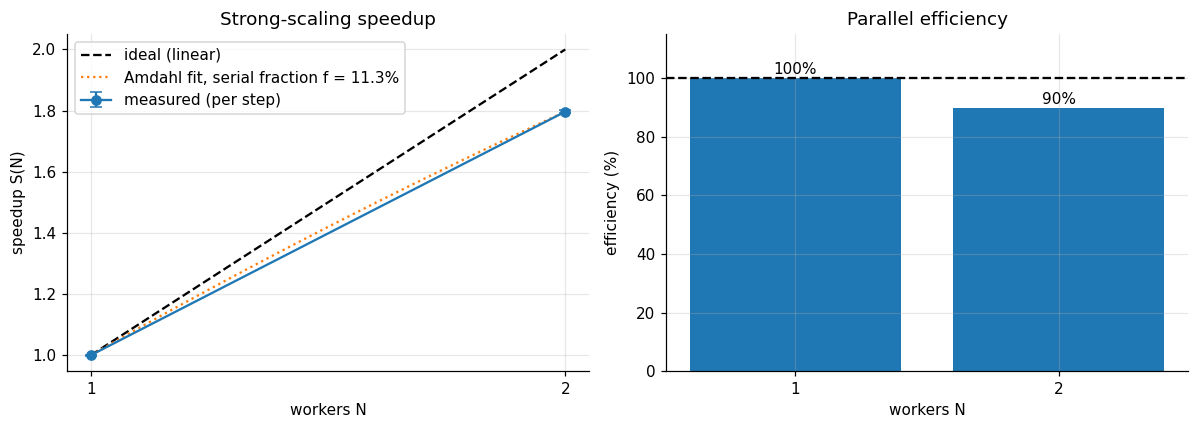

Fitted serial fraction f = 11.32% -> maximum achievable speedup 1/f = 8.8x


In [11]:
strong = scaling_table(df, "strong")
if len(strong): display(strong[["N", "runs", "step_ms", "step_ms_std", "speedup", "efficiency", "comm_frac",
                "tta_s", "tta_speedup", "l2_u", "l2_v", "l2_p", "sync_diff"]])

if len(strong) > 1:
    f_hat = fit_amdahl(strong.N, strong.speedup)
    Ns = np.linspace(1, strong.N.max(), 100)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(Ns, Ns, "k--", label="ideal (linear)")
    ax[0].errorbar(strong.N, strong.speedup,
                   yerr=strong.speedup * strong.step_ms_std.fillna(0) / strong.step_ms,
                   fmt="o-", capsize=4, label="measured (per step)")
    if strong.tta_speedup.notna().all():
        ax[0].plot(strong.N, strong.tta_speedup, "s-", label="measured (time-to-accuracy)")
    ax[0].plot(Ns, amdahl(Ns, f_hat), ":", label=f"Amdahl fit, serial fraction f = {f_hat:.1%}")
    ax[0].set(xlabel="workers N", ylabel="speedup S(N)", title="Strong-scaling speedup", xticks=strong.N)
    ax[0].legend()
    ax[1].bar(strong.N.astype(str), 100 * strong.efficiency, color="tab:blue")
    ax[1].axhline(100, ls="--", c="k")
    for x, e in zip(strong.N.astype(str), strong.efficiency):
        ax[1].text(x, 100 * e + 1.5, f"{e:.0%}", ha="center")
    ax[1].set(xlabel="workers N", ylabel="efficiency (%)", title="Parallel efficiency", ylim=(0, 115))
    fig.tight_layout(); fig.savefig(FIG / "strong_scaling.png", dpi=160, bbox_inches="tight"); plt.show()
    print(f"Fitted serial fraction f = {f_hat:.2%} -> maximum achievable speedup 1/f = {1/max(f_hat,1e-9):.1f}x")

### 7.2 Weak scaling: fixed work per worker, bigger problem

,N,runs,step_ms,step_ms_std,efficiency,scaled_speedup,throughput,comm_frac
0,1,3,86.01,0.09459,1,1,3.81e+05,0
1,2,3,86.51,0.1713,0.9941,1.988,7.575e+05,0.005377


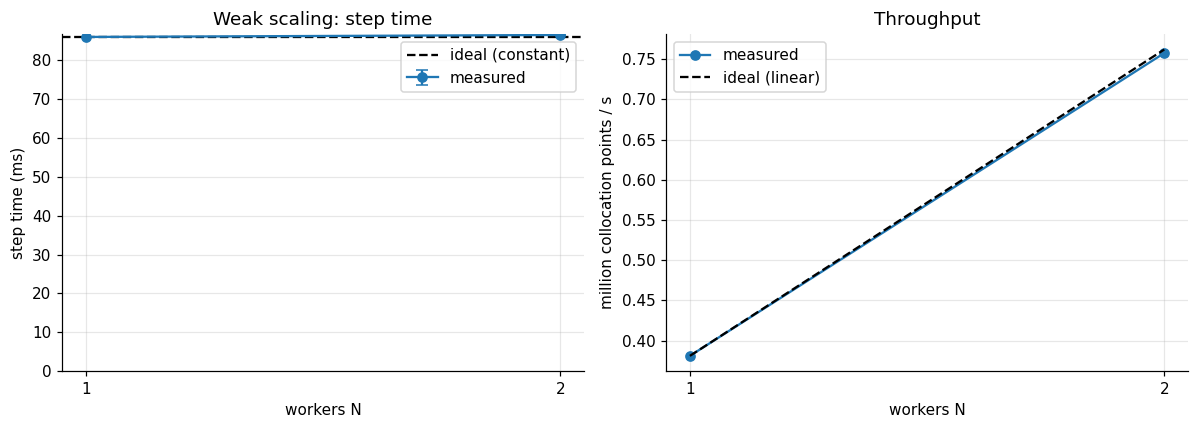

In [12]:
weak = scaling_table(df, "weak")
if len(weak) > 1:
    display(weak[["N", "runs", "step_ms", "step_ms_std", "efficiency", "scaled_speedup", "throughput", "comm_frac"]])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].errorbar(weak.N, weak.step_ms, yerr=weak.step_ms_std.fillna(0), fmt="o-", capsize=4, label="measured")
    ax[0].axhline(weak.step_ms.iloc[0], ls="--", c="k", label="ideal (constant)")
    ax[0].set(xlabel="workers N", ylabel="step time (ms)", title="Weak scaling: step time", xticks=weak.N, ylim=(0, None))
    ax[0].legend()
    ax[1].plot(weak.N, weak.throughput / 1e6, "o-", label="measured")
    ax[1].plot(weak.N, weak.throughput.iloc[0] / 1e6 * weak.N / weak.N.iloc[0], "k--", label="ideal (linear)")
    ax[1].set(xlabel="workers N", ylabel="million collocation points / s", title="Throughput", xticks=weak.N)
    ax[1].legend()
    fig.tight_layout(); fig.savefig(FIG / "weak_scaling.png", dpi=160, bbox_inches="tight"); plt.show()

### 7.3 Convergence: does splitting the work change the learning?

In strong scaling every worker count solves the same problem, so the curves can be compared directly. The **step axis** shows whether the optimisation itself changes. The **wall-time axis** shows the practical gain.

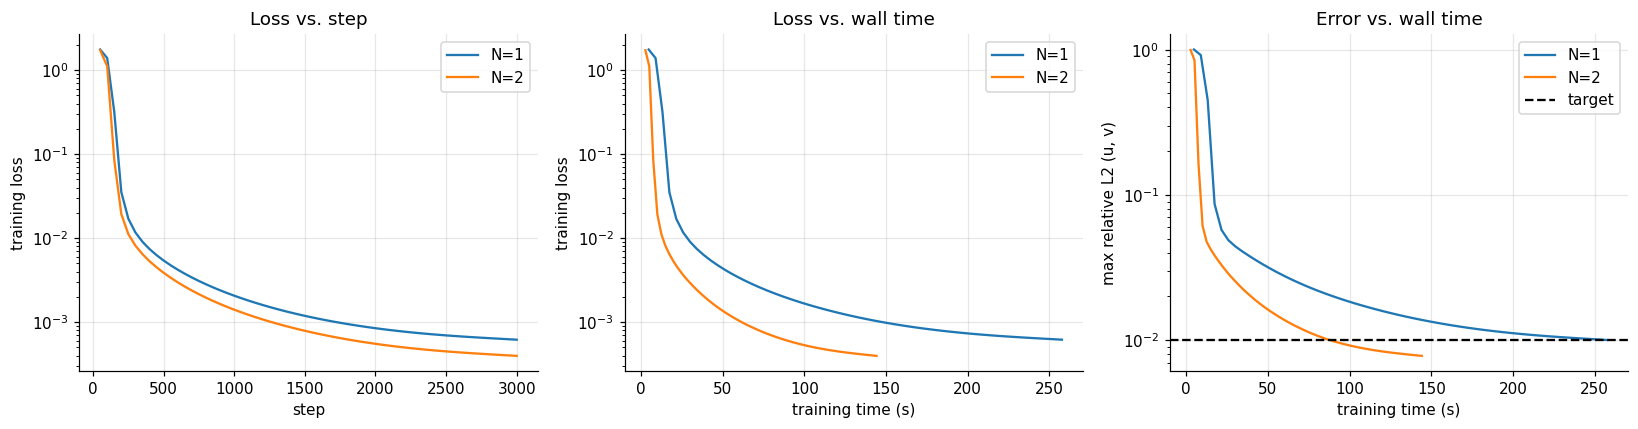

In [13]:
runs = load_runs(ROOT / "results" / TAG)
hist = {r["env"]["world"]: pd.DataFrame(r["history"]) for r in runs
        if r["config"]["scaling"] == "strong" and r["config"]["seed"] == 0}

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for n, h in sorted(hist.items()):
    ax[0].semilogy(h.step, h.loss, label=f"N={n}")
    ax[1].semilogy(h.train_time, h.loss, label=f"N={n}")
    ax[2].semilogy(h.train_time, np.maximum(h.l2_u, h.l2_v), label=f"N={n}")
ax[2].axhline(TARGET_L2, ls="--", c="k", label="target")
ax[0].set(xlabel="step", ylabel="training loss", title="Loss vs. step")
ax[1].set(xlabel="training time (s)", ylabel="training loss", title="Loss vs. wall time")
ax[2].set(xlabel="training time (s)", ylabel="max relative L2 (u, v)", title="Error vs. wall time")
for a in ax: a.legend()
fig.tight_layout(); fig.savefig(FIG / "convergence.png", dpi=160, bbox_inches="tight"); plt.show()

### 7.4 Learning-rate ablation at the largest worker count

Same problem and worker count, three learning-rate rules: no scaling ($\eta_1$), $\sqrt{N}$ scaling and linear scaling ($N\eta_1$).

$ /usr/bin/python3 benchmark.py --launcher torchrun --tag bench_lr-none --nprocs 2 --scaling strong --repeats 1 --steps 3000 --n_colloc 32768 --target_l2 0.01 --device cuda --log_every 50 --lr_scaling none
1 runs | nprocs=[2] | scaling=['strong'] | launcher=torchrun

=== [1/1] strong scaling | N=2 | seed=0
$ /usr/bin/python3 -m torch.distributed.run --standalone --nproc_per_node=2 /kaggle/working/parallel-pinn-hpc/train.py --steps 3000 --n_colloc 32768 --target_l2 0.01 --device cuda --log_every 50 --lr_scaling none --scaling strong --seed 0 --tag bench_lr-none --out /kaggle/working/parallel-pinn-hpc/results

*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************
[W923 23:27:41.658966177 socket.cpp:207] [c10d] The hostname of the client socket cannot b

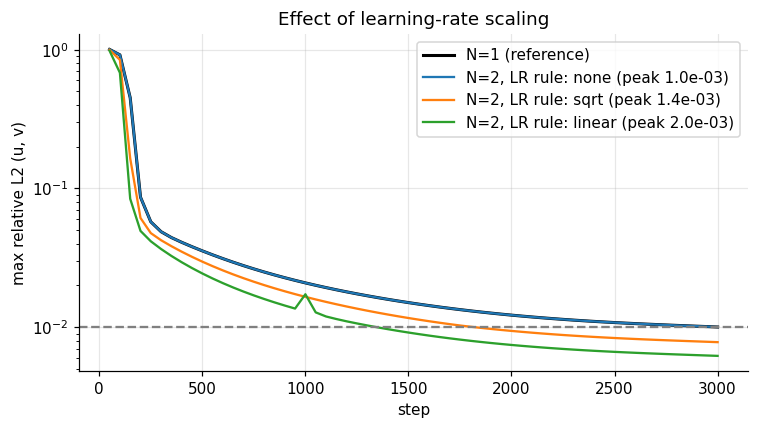

,lr_rule,peak_lr,final_l2_u,final_l2_v,time_to_target_s,step_to_target
0,none,0.001,0.01001,0.01003,NaN,NaN
1,sqrt,0.001414,0.007802,0.007641,88.59,"1,850"
2,linear,0.002,0.006214,0.006043,64.37,"1,350"


In [14]:
N_MAX = max(NPROCS)
if RUN_LR_ABLATION and N_MAX > 1:
    for rule in ("none", "sqrt", "linear"):
        sweep(f"{TAG}_lr-{rule}", [N_MAX], ["strong"], 1, TRAIN_ARGS + ["--lr_scaling", rule])

    fig, ax = plt.subplots(figsize=(7, 4))
    h1 = hist.get(1)
    if h1 is not None:
        ax.semilogy(h1.step, np.maximum(h1.l2_u, h1.l2_v), "k-", lw=2, label="N=1 (reference)")
    abl = []
    for rule in ("none", "sqrt", "linear"):
        r = load_runs(ROOT / "results" / f"{TAG}_lr-{rule}")[0]
        h = pd.DataFrame(r["history"])
        ax.semilogy(h.step, np.maximum(h.l2_u, h.l2_v), label=f"N={N_MAX}, LR rule: {rule} (peak {r['peak_lr']:.1e})")
        abl.append({"lr_rule": rule, "peak_lr": r["peak_lr"], "final_l2_u": r["final_l2"]["u"],
                    "final_l2_v": r["final_l2"]["v"], "time_to_target_s": r["time_to_target"],
                    "step_to_target": r["step_to_target"]})
    ax.axhline(TARGET_L2, ls="--", c="grey")
    ax.set(xlabel="step", ylabel="max relative L2 (u, v)", title="Effect of learning-rate scaling")
    ax.legend(); fig.tight_layout(); fig.savefig(FIG / "lr_ablation.png", dpi=160, bbox_inches="tight"); plt.show()
    display(pd.DataFrame(abl))

### 7.5 Where does the time go? Communication vs. computation

`DDP.no_sync()` disables the gradient all-reduce, so comparing step time with and without it isolates the communication cost that is **not hidden** behind the backward pass.

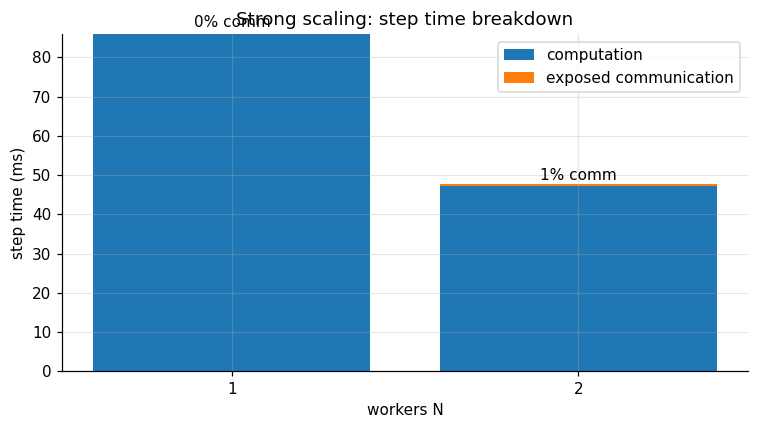

In [15]:
if len(strong) > 1:
    fig, ax = plt.subplots(figsize=(7, 4))
    comp = strong.step_ms * (1 - strong.comm_frac)
    ax.bar(strong.N.astype(str), comp, label="computation")
    ax.bar(strong.N.astype(str), strong.step_ms - comp, bottom=comp, label="exposed communication")
    for x, s, c in zip(strong.N.astype(str), strong.step_ms, strong.comm_frac):
        ax.text(x, s * 1.02, f"{c:.0%} comm", ha="center")
    ax.set(xlabel="workers N", ylabel="step time (ms)", title="Strong scaling: step time breakdown")
    ax.legend(); fig.tight_layout(); fig.savefig(FIG / "comm_breakdown.png", dpi=160, bbox_inches="tight"); plt.show()

### 7.6 The learned flow field

Prediction of the largest strong-scaling run at $t = T$, compared with the exact solution.

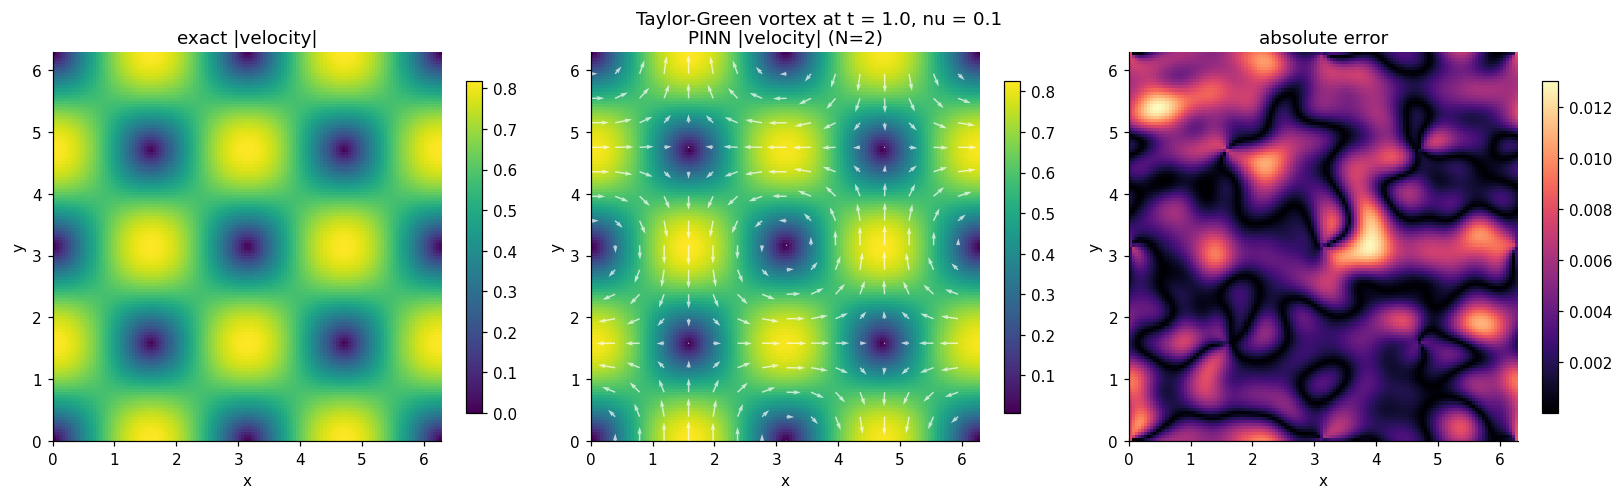

In [16]:
pick = max((r for r in runs if r["config"]["scaling"] == "strong" and r["config"]["seed"] == 0),
           key=lambda r: r["env"]["world"])
c = pick["config"]
model = PINN(c["width"], c["depth"], c["n_freq"], c["t_max"])
ckpt = ROOT / "results" / TAG / "strong" / f"N{pick['env']['world']}_seed0.pt"
model.load_state_dict(torch.load(ckpt, map_location="cpu"))
model.eval()

n = 128
xs = torch.linspace(0, 2 * np.pi, n)
xx, yy = torch.meshgrid(xs, xs, indexing="ij")
X = torch.stack([xx.ravel(), yy.ravel(), torch.full((n * n,), c["t_max"])], 1)
with torch.no_grad():
    pred, exact = model(X), taylor_green(X, c["nu"])
speed = lambda U: torch.sqrt(U[:, 0] ** 2 + U[:, 1] ** 2).reshape(n, n).numpy()
panels = [(speed(exact), "exact |velocity|"), (speed(pred), f"PINN |velocity| (N={pick['env']['world']})"),
          (np.abs(speed(pred) - speed(exact)), "absolute error")]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, (Z, title) in zip(ax, panels):
    im = a.imshow(Z.T, origin="lower", extent=[0, 2 * np.pi] * 2, cmap="magma" if "error" in title else "viridis")
    a.set(title=title, xlabel="x", ylabel="y"); a.grid(False); fig.colorbar(im, ax=a, shrink=0.85)
s = slice(None, None, 8)
ax[1].quiver(xx.numpy()[s, s], yy.numpy()[s, s], pred[:, 0].reshape(n, n).numpy()[s, s],
             pred[:, 1].reshape(n, n).numpy()[s, s], color="w", alpha=0.7)
fig.suptitle(f"Taylor-Green vortex at t = {c['t_max']}, nu = {c['nu']}")
fig.tight_layout(); fig.savefig(FIG / "flow_field.png", dpi=160, bbox_inches="tight"); plt.show()

### 7.7 Automatic summary

This summary is generated from the measured numbers above, so it is always consistent with the data.

In [17]:
lines = [f"Hardware: {df.device.iloc[0]} | worker counts: {sorted(df.N.unique())} | seeds per config: {df.groupby(['scaling','N']).seed.count().min()}"]
if len(strong) > 1:
    last = strong.iloc[-1]
    lines.append(f"Strong scaling: {last.N:.0f} workers -> {last.speedup:.2f}x per-step speedup "
                 f"({last.efficiency:.0%} efficiency), fitted serial fraction {fit_amdahl(strong.N, strong.speedup):.1%}.")
    if pd.notna(last.tta_speedup):
        lines.append(f"Time-to-accuracy (L2 < {TARGET_L2:g}): {strong.tta_s.iloc[0]:.1f}s on 1 worker vs "
                     f"{last.tta_s:.1f}s on {last.N:.0f} -> {last.tta_speedup:.2f}x real speedup.")
    lines.append(f"Final relative L2 (u): {strong.l2_u.iloc[0]:.2e} on 1 worker vs {last.l2_u:.2e} on {last.N:.0f}.")
    lines.append(f"Exposed communication at {last.N:.0f} workers: {last.comm_frac:.0%} of the step.")
    lines.append(f"Weights identical across ranks: max difference {strong.sync_diff.max():.1e}.")
if len(weak) > 1:
    lw = weak.iloc[-1]
    lines.append(f"Weak scaling: {lw.efficiency:.0%} efficiency at {lw.N:.0f} workers "
                 f"(throughput x{lw.scaled_speedup:.2f}).")
print("\n".join(lines))
(FIG / "summary.txt").write_text("\n".join(lines))

Hardware: Tesla T4 | worker counts: [np.int64(1), np.int64(2)] | seeds per config: 3
Strong scaling: 2 workers -> 1.80x per-step speedup (90% efficiency), fitted serial fraction 11.3%.
Final relative L2 (u): 1.28e-02 on 1 worker vs 9.87e-03 on 2.
Exposed communication at 2 workers: 1% of the step.
Weights identical across ranks: max difference 0.0e+00.
Weak scaling: 99% efficiency at 2 workers (throughput x1.99).


416